## **Exploratory Data Analysis(EDA) Using Pandas**

### **What is EDA?**
EDA(Exploratory Data Analysis) is the process of examining a dataset to summarize its main characterstics, often using visual methods.

#### **It helps us:**
- Detect patterns and relationships
- Identify acomalies or outliers
- Handle missing values 
- Prepare data for modeling     

## **Why Use Pandas for EDA**
Pandas is the most widely-used Python library for data manipulation and analysis.

## **Step-by-Step EDA on Real-World Dataset**
- Data Review,intial,inspection
- Missing value detection and imputation
- Outlier detection and handling

In [1]:
import pandas as pd

#### **Dataset Overview and Intial Inspection** 

In [2]:
# Load Dataset
df = pd.read_csv(r"c:\Users\LENOVO\Downloads\data_clean.csv")

In [3]:
df.head()

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
0,1,41.0,190.0,7.4,67,5,1,2010,67,S
1,2,36.0,118.0,8.0,72,5,2,2010,72,C
2,3,12.0,149.0,12.6,74,5,3,2010,74,PS
3,4,18.0,313.0,11.5,62,5,4,2010,62,S
4,5,NaN,NaN,14.3,56,5,5,2010,56,S


In [4]:
df_bkup = df # Taking up before any changes , so we can restore any point of time

In [5]:
df.tail(10)

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
148,149,30.0,193.0,6.9,70,9,26,2010,70,C
149,150,NaN,145.0,13.2,77,9,27,2010,77,PS
150,151,14.0,191.0,14.3,75,9,28,2010,75,S
151,152,18.0,131.0,8.0,76,9,29,2010,76,PS
152,153,20.0,223.0,11.5,68,9,30,2010,68,S
153,154,41.0,190.0,7.4,67,5,1,2010,67,C
154,155,30.0,193.0,6.9,70,9,26,2010,70,PS
155,156,NaN,145.0,13.2,77,9,27,2010,77,S
156,157,14.0,191.0,14.3,75,9,28,2010,75,S
157,158,18.0,131.0,8.0,76,9,29,2010,76,C


In [6]:
df.shape #Dimension of dataset

(158, 10)

In [7]:
df.dtypes # Data Types

Unnamed: 0      int64
Ozone         float64
Solar.R       float64
Wind          float64
Temp C         object
Month          object
Day             int64
Year            int64
Temp            int64
Weather        object
dtype: object

In [8]:
df.describe() # Basic Statistics
# Only work for int,float values

,Unnamed: 0,Ozone,Solar.R,Wind,Day,Year,Temp
count,158.000000,120.000000,151.000000,158.000000,158.000000,158.0,158.000000
mean,79.500000,41.583333,185.403974,9.957595,16.006329,2010.0,77.727848
std,45.754781,32.620709,88.723103,3.511261,8.997166,0.0,9.377877
min,1.000000,1.000000,7.000000,1.700000,1.000000,2010.0,56.000000
25%,40.250000,18.000000,119.000000,7.400000,8.000000,2010.0,72.000000
50%,79.500000,30.500000,197.000000,9.700000,16.000000,2010.0,78.500000
75%,118.750000,61.500000,257.000000,11.875000,24.000000,2010.0,84.000000
max,158.000000,168.000000,334.000000,20.700000,31.000000,2010.0,97.000000


## **Data Type Conversion:**

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  158 non-null    int64  
 1   Ozone       120 non-null    float64
 2   Solar.R     151 non-null    float64
 3   Wind        158 non-null    float64
 4   Temp C      158 non-null    object 
 5   Month       158 non-null    object 
 6   Day         158 non-null    int64  
 7   Year        158 non-null    int64  
 8   Temp        158 non-null    int64  
 9   Weather     155 non-null    object 
dtypes: float64(3), int64(4), object(3)
memory usage: 12.5+ KB


Sometimes few of data point have wronge values and we didnt find during EDA,

during machine learning model , it through an error , as it is string and expected as numeric,

like here month, is numeric value ,so we convert from object to numeric

In [10]:
#df['Month'] =pd.to_numeric(df['Month'])
## It show an error

In [11]:
df['Month'].head(25) # It show 'May' , We need to handle this.

0       5
1       5
2       5
3       5
4       5
5       5
6       5
7       5
8       5
9       5
10      5
11      5
12      5
13      5
14      5
15      5
16      5
17      5
18      5
19      5
20      5
21      5
22      5
23    May
24      5
Name: Month, dtype: object

In [12]:
# Since May is invalid let us replace with 5
df['Month']=df['Month'].replace('May',5)

In [13]:
df['Month'].head(25) # check error is fixed

0     5
1     5
2     5
3     5
4     5
5     5
6     5
7     5
8     5
9     5
10    5
11    5
12    5
13    5
14    5
15    5
16    5
17    5
18    5
19    5
20    5
21    5
22    5
23    5
24    5
Name: Month, dtype: object

In [14]:
df['Month']= pd.to_numeric(df['Month'],errors='coerce') # errors= 'coerce' force to convert any value like May to NA
df['Temp C']=pd.to_numeric(df['Temp C'],errors='coerce')
df['Weather']=df['Weather'].astype('category')


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   Unnamed: 0  158 non-null    int64   
 1   Ozone       120 non-null    float64 
 2   Solar.R     151 non-null    float64 
 3   Wind        158 non-null    float64 
 4   Temp C      157 non-null    float64 
 5   Month       158 non-null    int64   
 6   Day         158 non-null    int64   
 7   Year        158 non-null    int64   
 8   Temp        158 non-null    int64   
 9   Weather     155 non-null    category
dtypes: category(1), float64(4), int64(5)
memory usage: 11.5 KB


## **Duplicates**


In [16]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
153    False
154    False
155    False
156    False
157    False
Length: 158, dtype: bool

In [17]:
# Count of duplicated rows
df[df.duplicated()].shape

(0, 10)

In [18]:
# This indicates , there is no duplicate records

In [19]:
# print the dublicate rows
df[df.duplicated()]

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather


In [20]:
# In case of dupicated records found, it need to drop as follows.
df=df.drop_duplicates()
df.shape

(158, 10)

## **Drop columns which are unnecessary**

In [21]:
# droping 'unnamed: 0' 'column' as it is found unnecessary
df.head(2)

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
0,1,41.0,190.0,7.4,67.0,5,1,2010,67,S
1,2,36.0,118.0,8.0,72.0,5,2,2010,72,C


In [22]:
df_bkup1=df # Taking back up one more time before removing anything

In [23]:
df= df.drop('Unnamed: 0',axis=1)

In [24]:
df.head(4)

,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
0,41.0,190.0,7.4,67.0,5,1,2010,67,S
1,36.0,118.0,8.0,72.0,5,2,2010,72,C
2,12.0,149.0,12.6,74.0,5,3,2010,74,PS
3,18.0,313.0,11.5,62.0,5,4,2010,62,S


In [25]:
# Droping 'Temp C' column as , Temp C and Temp Having dame data

In [26]:
df=df.drop("Temp C",axis=1)

In [27]:
df.head()

,Ozone,Solar.R,Wind,Month,Day,Year,Temp,Weather
0,41.0,190.0,7.4,5,1,2010,67,S
1,36.0,118.0,8.0,5,2,2010,72,C
2,12.0,149.0,12.6,5,3,2010,74,PS
3,18.0,313.0,11.5,5,4,2010,62,S
4,NaN,NaN,14.3,5,5,2010,56,S


## **Rename the columns**

In [28]:
# Rename the solar column
df= df.rename({'Solar.R':'Solar'},axis=1)

In [29]:
df.head()

,Ozone,Solar,Wind,Month,Day,Year,Temp,Weather
0,41.0,190.0,7.4,5,1,2010,67,S
1,36.0,118.0,8.0,5,2,2010,72,C
2,12.0,149.0,12.6,5,3,2010,74,PS
3,18.0,313.0,11.5,5,4,2010,62,S
4,NaN,NaN,14.3,5,5,2010,56,S


## **Why Handle Missing Values?**
- Algorithms cannot handle null/NAN values.
- Imputing them reduces bias and maintains dataset unstability.


## **How To Find Missing Values**

In [30]:
cols = df.columns
cols

Index(['Ozone', 'Solar', 'Wind', 'Month', 'Day', 'Year', 'Temp', 'Weather'], dtype='object')

<Axes: >

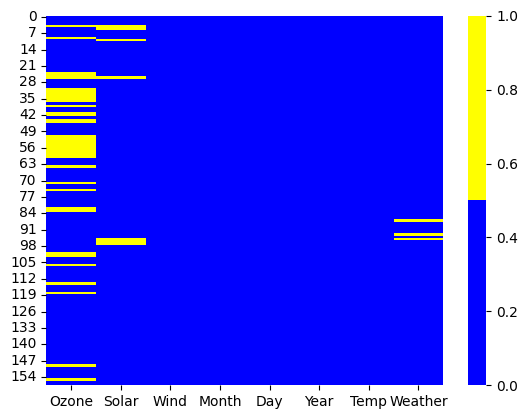

In [31]:
import seaborn as sns 
cols = df.columns
colours = ['blue',"yellow"] # Specify the colours - yellow for missing. blue is not missing.
sns.heatmap(df[cols].isnull(),cmap=sns.color_palette(colours))

In [32]:
# Inferance
# column named "ozone" has most nan values,where solar nd wheather columns have few one.

In [33]:
df.isnull().sum()

Ozone      38
Solar       7
Wind        0
Month       0
Day         0
Year        0
Temp        0
Weather     3
dtype: int64

In [34]:
print('Missing in Ozone:',df['Ozone'].isnull().sum())

Missing in Ozone: 38


In [35]:
# Check Wheather Ozone has outlier or not

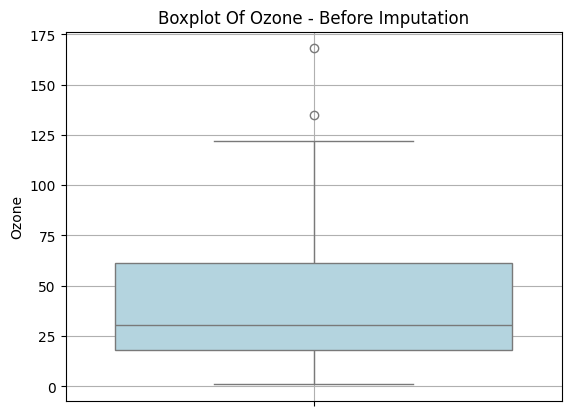

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns 
# Box plot for outliers
plt.Figure(figsize=(8,5))
sns.boxplot(y=df['Ozone'],color='lightblue')
plt.title("Boxplot Of Ozone - Before Imputation")
plt.grid()
plt.show()

In [37]:
# There are outliers , still we confirm with one stastistical method.

In [38]:
# Calculate Q1 and Q3 
Q1 =df['Ozone'].quantile(0.25)
Q3 = df['Ozone'].quantile(0.75)
IQR = Q3 - Q1

#Define Outliers bounds
lower_bound = Q1- 1.5* IQR
upper_bound = Q3+ 1.5* IQR

#Find Outliers
outliers = df[(df['Ozone']<lower_bound)|(df['Ozone']> upper_bound)]
print("Number of outliers in ozone column:",outliers.shape[0])

Number of outliers in ozone column: 2


In [39]:
# hence as per stratgey , we will replace Solar nan with mean

In [40]:
#Fill with meadium
ozone_medium= df['Ozone'].median()
df['Ozone'].fillna(ozone_medium,inplace=True)
print('Filled with medium: ',ozone_medium)

Filled with medium:  30.5


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6728\4246742671.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Ozone'].fillna(ozone_medium,inplace=True)


In [41]:
# Check missing in Ozone
print(f"Missing in Ozone: {df['Ozone'].isnull().sum()}")

Missing in Ozone: 0


In [42]:
print(f"Missing values before: {df['Solar'].isnull().sum()}")

Missing values before: 7


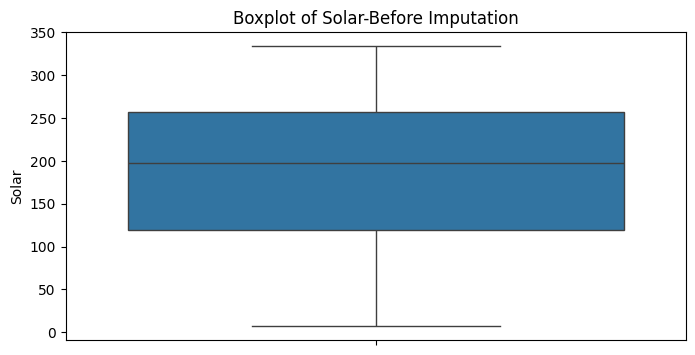

In [43]:
# Now Boxplot to check outliers in solar Feature(column)
plt.figure(figsize=(8,4))
sns.boxplot(y=df['Solar'])
plt.title("Boxplot of Solar-Before Imputation")
plt.show()


In [44]:
# Replace na with mean of the "solar" , as no outlier present
mean_value=df['Solar'].mean()
df['Solar'].fillna(mean_value,inplace=True)
print(f"Solar Mean Value: {mean_value}")

Solar Mean Value: 185.40397350993376


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6728\3789555279.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Solar'].fillna(mean_value,inplace=True)


In [45]:
print(f"Missing Values After: {df['Solar'].isnull().sum()}")

Missing Values After: 0


In [46]:
print(f"Missing Values before: {df['Weather'].isnull().sum()}")

Missing Values before: 3


In [47]:
# Check most frequent value(mode)
mode_value = df['Weather'].mode()[0]
mode_value

'S'

In [48]:
# Replacing NAN with mode
df['Weather'].fillna(mode_value,inplace=True)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6728\3985041985.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Weather'].fillna(mode_value,inplace=True)


In [49]:
df.isnull().sum()

Ozone      0
Solar      0
Wind       0
Month      0
Day        0
Year       0
Temp       0
Weather    0
dtype: int64

## **How to Detect OUTLIER**

<Axes: >

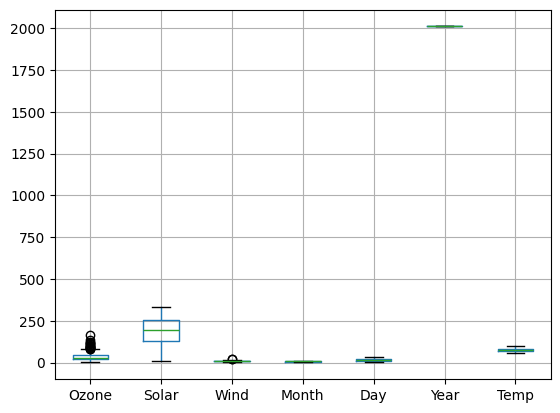

In [50]:
df.boxplot()

In [51]:
# Ozone and Wind column has few outliers
# Calculate Q1 and Q3 
Q1 =df['Wind'].quantile(0.25)
Q3 = df['Wind'].quantile(0.75)
IQR = Q3 - Q1

#Define Outliers bounds
lower_bound = Q1- 1.5* IQR
upper_bound = Q3+ 1.5* IQR

#Find Outliers
outliers = df[(df['Wind']<lower_bound)|(df['Wind']> upper_bound)]
print("Number of outliers in Wind column:",outliers.shape[0])

Number of outliers in Wind column: 2


In [52]:
median_value = df['Wind'].median()
median_value

np.float64(9.7)

In [53]:
# Replacing Outliers with median
df.loc[df['Wind'] < lower_bound, 'Wind'] = median_value
df.loc[df['Wind'] > upper_bound,'Wind'] = median_value

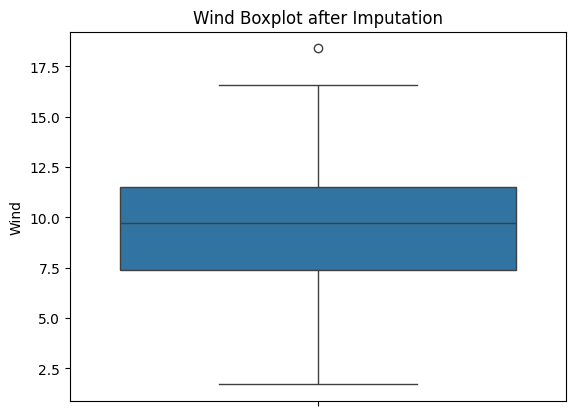

In [54]:
# To confirm outliers imputed
plt.Figure(figsize=(8,5))
sns.boxplot(df['Wind'])
plt.title("Wind Boxplot after Imputation")
plt.show()

**Note:** After imputation, sometimes boxplot may still show some points due to recalculated IQR based on new data.

These are not necessarily bad data, just statistical boundaries shifting.

In [55]:
outliers = df[(df['Wind'] < lower_bound)|(df['Wind']> upper_bound)]
print("Number of outliers in wind column:",outliers.shape[0])

Number of outliers in wind column: 0


In [56]:
# Similarly for Ozone feature(column)

In [57]:
Q1 = df['Ozone'].quantile(0.25)
Q3 = df['Ozone'].quantile(0.75)
IQR = Q3-Q1

# Define outlier bounds
lower_bound = Q1-1.5*IQR
upper_bound = Q3+1.5*IQR

# Find Outliers
outliers1 = df[(df['Ozone'] < lower_bound ) | (df['Ozone'] > upper_bound)]
print("Number of Outliers in Ozone",outliers1.shape[0])

Number of Outliers in Ozone 16


In [58]:
median_value1 = df['Ozone'].median()
median_value1

np.float64(30.5)

In [59]:
# Replace outliers with median
df.loc[df['Ozone'] < lower_bound,'Ozone'] = median_value1
df.loc[df['Ozone'] > upper_bound,'Ozone'] = median_value1

In [60]:
outliers1 = df[(df['Ozone'] < lower_bound)|(df['Ozone']> upper_bound)]
print("Number of outliers: ",outliers1.shape[0])

Number of outliers:  0


## **Scatterplot and Correalation analysis** 

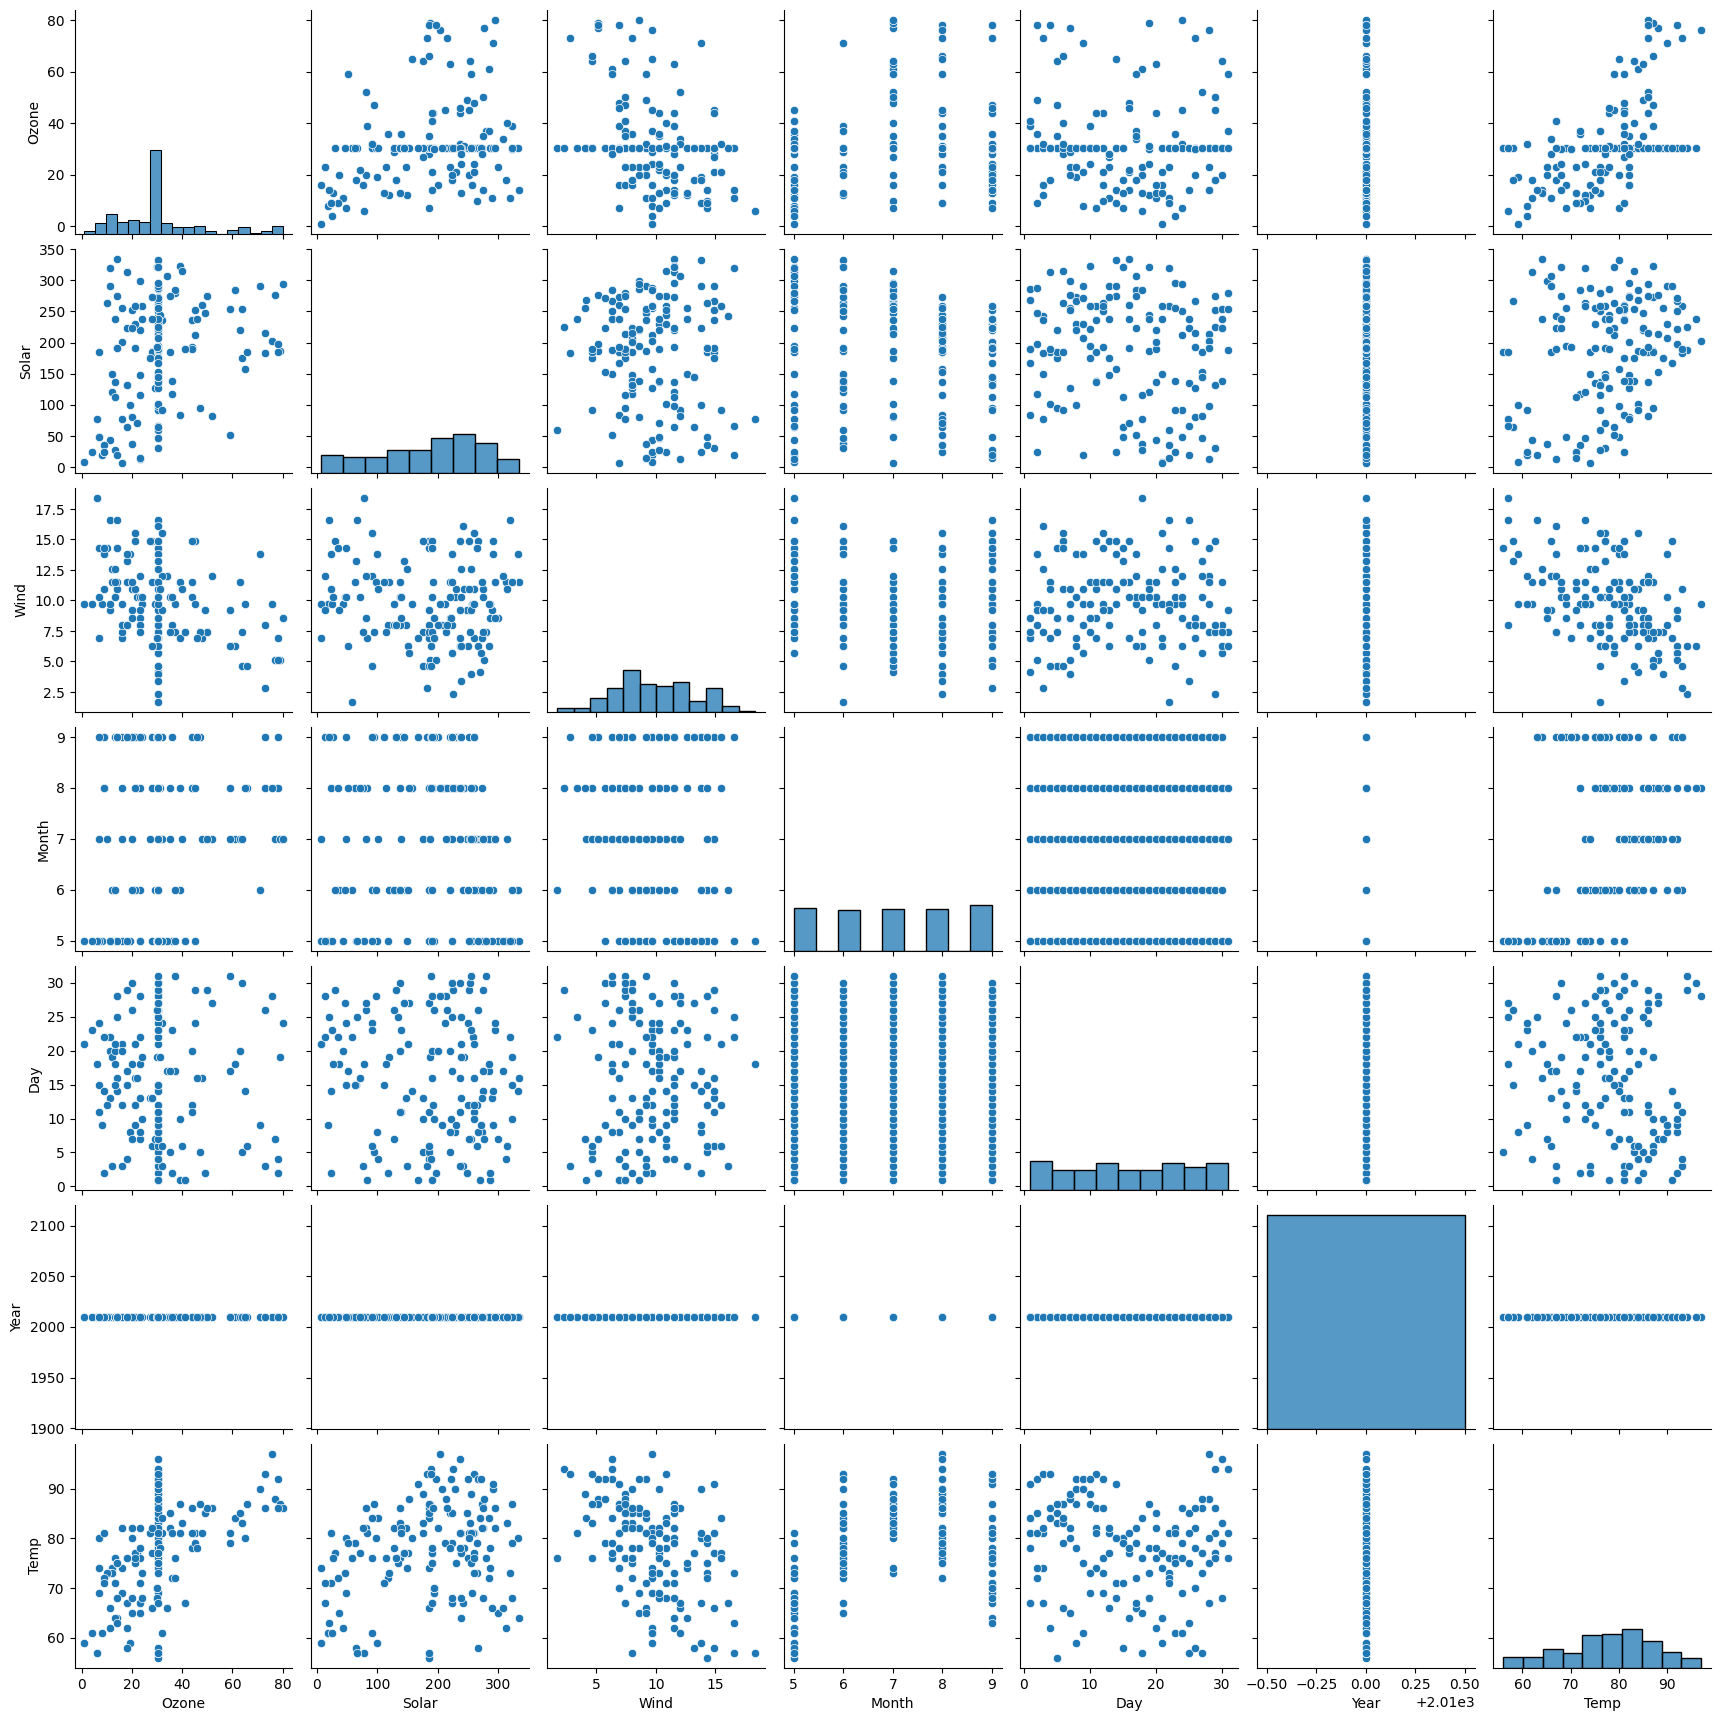

In [61]:
import seaborn as sns
sns.pairplot(df)

In [62]:
## Correlation
#df.corr() # It through an error
df.select_dtypes(include='number').corr()

,Ozone,Solar,Wind,Month,Day,Year,Temp
Ozone,1.000000,0.288578,-0.354190,0.120973,-0.066719,NaN,0.511967
Solar,0.288578,1.000000,-0.044178,-0.079196,-0.149606,NaN,0.260473
Wind,-0.354190,-0.044178,1.000000,-0.123958,0.055928,NaN,-0.420121
Month,0.120973,-0.079196,-0.123958,1.000000,0.052646,NaN,0.402942
Day,-0.066719,-0.149606,0.055928,0.052646,1.000000,NaN,-0.124538
Year,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Temp,0.511967,0.260473,-0.420121,0.402942,-0.124538,NaN,1.000000


In [63]:
# Hence co relations value like Temp with Ozone is 0.51 which shows it is positive correlation 
#  Similarly There is negative co relation between wind with Ozone , -0.35, which is more

## **Dummy Variable**

### What is a Dummy Variable?

A **dummy variable** is a numeric(0/1) representation of **categorical data** in machine learning and statistical models.

## **Why is it Required?**
- Most algorithms **cannot understand text**- they need numbers.
- Dummy variables **convert categories into binary format**,allowing models toprocess them effectively.
- For example: a column `Gender` with values `Male` and `Female` becomes:

     Gender_Male (0)  |   Gender_Female(1)

In [64]:
df.head()

,Ozone,Solar,Wind,Month,Day,Year,Temp,Weather
0,41.0,190.000000,7.4,5,1,2010,67,S
1,36.0,118.000000,8.0,5,2,2010,72,C
2,12.0,149.000000,12.6,5,3,2010,74,PS
3,18.0,313.000000,11.5,5,4,2010,62,S
4,30.5,185.403974,14.3,5,5,2010,56,S


In [65]:
# Creating a dummy variable for Weather column
#df=pd.get_dummies(df,columns=['Weather'])

In [66]:
#Wheather column is converted into Weather_C,Weather_PS,and Weather_s are created with one column
# value as 1 ,rest are 0

In [67]:
# Note: If Weather_c,Weather_ps,Weather_S columns shows values like true, false insted of 0 and 1 
# use following code.
df=pd.get_dummies(df,columns=['Weather']).astype(int)  # convert into int will resolve an issue

In [68]:
df

,Ozone,Solar,Wind,Month,Day,Year,Temp,Weather_C,Weather_PS,Weather_S
0,41,190,7,5,1,2010,67,0,0,1
1,36,118,8,5,2,2010,72,1,0,0
2,12,149,12,5,3,2010,74,0,1,0
3,18,313,11,5,4,2010,62,0,0,1
4,30,185,14,5,5,2010,56,0,0,1
...,...,...,...,...,...,...,...,...,...,...
153,41,190,7,5,1,2010,67,1,0,0
154,30,193,6,9,26,2010,70,0,1,0
155,30,145,13,9,27,2010,77,0,0,1
156,14,191,14,9,28,2010,75,0,0,1


# **Normalization of the data**

## **Normalization: The Basics**
- Normalization is a technique used in data preprocessing to scale the values of numerical features to a specific range.

This ensures that no features  dominates other purely due to its scale, Which is especially important for machine learning

 algorithms senstive to feature magnitudes(e.g gradient descent, k-NN)


- To common normalizaton technique are  StandardScalar and MinMaxScaler.

In [69]:
#Normalization of the data
from numpy import set_printoptions
from sklearn.preprocessing import MinMaxScaler

In [70]:
df.values

array([[ 41, 190,   7, ...,   0,   0,   1],
       [ 36, 118,   8, ...,   1,   0,   0],
       [ 12, 149,  12, ...,   0,   1,   0],
       ...,
       [ 30, 145,  13, ...,   0,   0,   1],
       [ 14, 191,  14, ...,   0,   0,   1],
       [ 18, 131,   8, ...,   1,   0,   0]], shape=(158, 10))

In [71]:
array = df.values
array

array([[ 41, 190,   7, ...,   0,   0,   1],
       [ 36, 118,   8, ...,   1,   0,   0],
       [ 12, 149,  12, ...,   0,   1,   0],
       ...,
       [ 30, 145,  13, ...,   0,   0,   1],
       [ 14, 191,  14, ...,   0,   0,   1],
       [ 18, 131,   8, ...,   1,   0,   0]], shape=(158, 10))

In [72]:
scaler = MinMaxScaler(feature_range=(0,1))
rescaledX = scaler.fit_transform(array)

In [73]:
# Transformed data
set_printoptions(precision=2)
print(rescaledX[0:5,:])

[[0.51 0.56 0.35 0.   0.   0.   0.27 0.   0.   1.  ]
 [0.44 0.34 0.41 0.   0.03 0.   0.39 1.   0.   0.  ]
 [0.14 0.43 0.65 0.   0.07 0.   0.44 0.   1.   0.  ]
 [0.22 0.94 0.59 0.   0.1  0.   0.15 0.   0.   1.  ]
 [0.37 0.54 0.76 0.   0.13 0.   0.   0.   0.   1.  ]]


In [74]:
#Standardize data (0 mean, 1 stdev)
from sklearn.preprocessing import StandardScaler

In [ ]:
# real world 
array = df.values # Convert dataframe into a numpy array,ML models works on numbers ,not column name
scaler = StandardScaler() 
scaler.fit(array) # mean of each column,standard deviation of each column
rescaledX=scaler.transform(array) # Applies the formula (x-mean)/std
 
#Summarize transformed data
set_printoptions(precision=2)
print(rescaledX[0:5,:])


[[ 0.59  0.05 -0.72 -1.42 -1.67  0.   -1.15 -0.67 -0.65  1.24]
 [ 0.29 -0.78 -0.41 -1.42 -1.56  0.   -0.61  1.49 -0.65 -0.8 ]
 [-1.15 -0.42  0.81 -1.42 -1.45  0.   -0.4  -0.67  1.54 -0.8 ]
 [-0.79  1.48  0.51 -1.42 -1.34  0.   -1.68 -0.67 -0.65  1.24]
 [-0.07 -0.    1.43 -1.42 -1.23  0.   -2.32 -0.67 -0.65  1.24]]


In [ ]:
# For bignner 
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)
scaled_data

array([[ 0.59,  0.05, -0.72, ..., -0.67, -0.65,  1.24],
       [ 0.29, -0.78, -0.41, ...,  1.49, -0.65, -0.8 ],
       [-1.15, -0.42,  0.81, ..., -0.67,  1.54, -0.8 ],
       ...,
       [-0.07, -0.47,  1.12, ..., -0.67, -0.65,  1.24],
       [-1.03,  0.06,  1.43, ..., -0.67, -0.65,  1.24],
       [-0.79, -0.63, -0.41, ...,  1.49, -0.65, -0.8 ]], shape=(158, 10))

In [ ]:
# here data has been normalized this data is generalized ,
# Hence it can be used , for further modeling where, model will not be biased on any feature